In [1]:
!pip install mysql-connector-python pandas matplotlib seaborn


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="root",
    database="library"
)

print("Database connected successfully!")

Database connected successfully!


In [6]:
if conn.is_connected():
    print("Connected to MySQL Database")

Connected to MySQL Database


In [7]:
query = "SELECT * FROM books"

df = pd.read_sql(query, conn)

df.head()

C:\Users\me\AppData\Local\Temp\ipykernel_7156\3619524551.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,id,category_id,description,isbn,language_id,pages,publication_year,publisher_id,title
0,1,16,Paperback,978-6-6618-6350-4,3,449,2007,43,Storm Night
1,2,3,Paperback,978-7-2672-4260-8,3,651,2016,1,Moon Glass Harbor Sister
2,3,7,Hardcover,978-1-6878-7600-8,1,496,1958,5,Sister Song Fire
3,4,5,Paperback,978-6-8743-2430-8,5,509,2019,30,Glass Winter Crown Kingdom
4,5,6,Paperback,978-6-6790-7727-0,3,380,2025,58,City Moon


In [12]:
print("Dataset Shape:", df.shape)

df.info()




Dataset Shape: (12, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   id                12 non-null     int64 
 1   category_id       12 non-null     int64 
 2   description       12 non-null     object
 3   isbn              12 non-null     object
 4   language_id       12 non-null     int64 
 5   pages             12 non-null     int64 
 6   publication_year  12 non-null     int64 
 7   publisher_id      12 non-null     int64 
 8   title             12 non-null     object
dtypes: int64(6), object(3)
memory usage: 996.0+ bytes


In [11]:
df.isnull().sum()

id                  0
category_id         0
description         0
isbn                0
language_id         0
pages               0
publication_year    0
publisher_id        0
title               0
dtype: int64

In [13]:
df.describe()

,id,category_id,language_id,pages,publication_year,publisher_id
count,12.000000,12.000000,12.000000,12.000000,12.000000,12.000000
mean,6.500000,7.250000,3.416667,502.166667,1997.166667,22.666667
std,3.605551,4.351071,2.906367,123.172336,24.749043,20.218503
min,1.000000,1.000000,1.000000,309.000000,1954.000000,1.000000
25%,3.750000,4.500000,1.000000,422.750000,1980.500000,4.250000
50%,6.500000,6.500000,3.000000,481.000000,2004.000000,19.500000
75%,9.250000,10.250000,3.500000,583.250000,2016.750000,40.000000
max,12.000000,16.000000,10.000000,742.000000,2025.000000,58.000000


In [14]:
df.columns

Index(['id', 'category_id', 'description', 'isbn', 'language_id', 'pages',
       'publication_year', 'publisher_id', 'title'],
      dtype='object')

In [15]:
query = """
SELECT b.title, COUNT(l.id) AS total_borrowings
FROM books b
JOIN copies c ON b.id = c.book_id
JOIN loans l ON c.id = l.copy_id
GROUP BY b.id, b.title
ORDER BY total_borrowings DESC
LIMIT 10;
"""

popular_books = pd.read_sql(query, conn)
popular_books

C:\Users\me\AppData\Local\Temp\ipykernel_7156\1879336367.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  popular_books = pd.read_sql(query, conn)


,title,total_borrowings
0,Sister Song Fire,241
1,Storm Night,206
2,Glass Winter Crown Kingdom,182
3,Winter Station Midnight,86
4,Distant Lost Station Silent,65
5,Moon Glass Harbor Sister,55
6,City Moon,35
7,Wild Light North Distant,34
8,Song Golden Burning Garden,32
9,Ocean Broken Iron,27


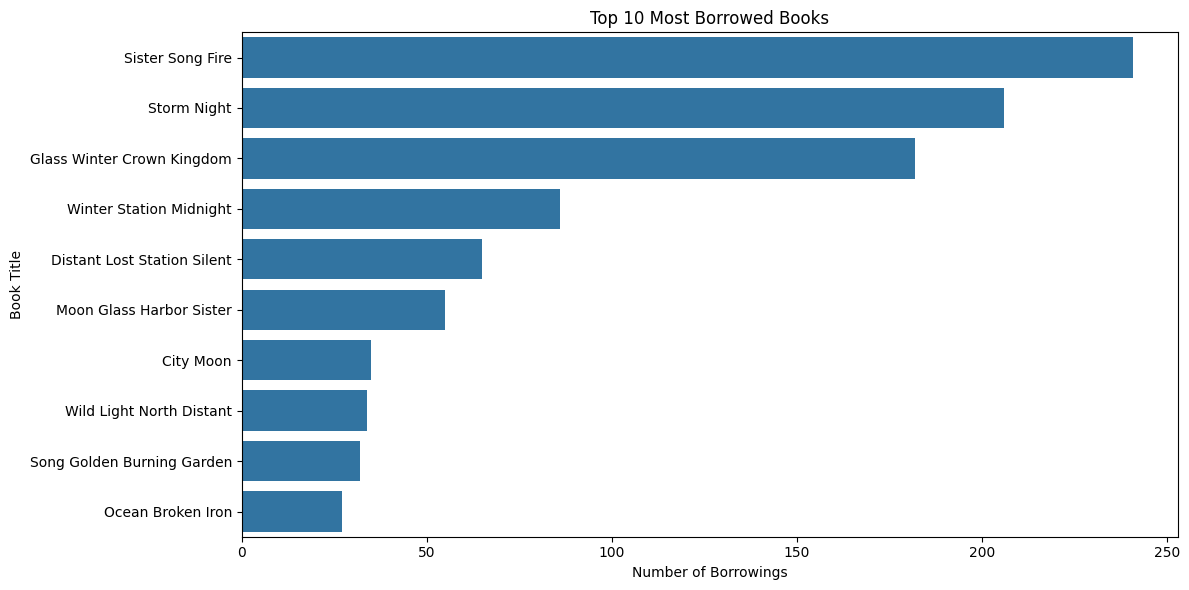

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

sns.barplot(
    data=popular_books,
    x='total_borrowings',
    y='title'
)

plt.title('Top 10 Most Borrowed Books')
plt.xlabel('Number of Borrowings')
plt.ylabel('Book Title')
plt.tight_layout()
plt.show()

In [17]:
query = """
SELECT
    DATE_FORMAT(loan_date, '%Y-%m') AS month,
    COUNT(*) AS total_borrowings
FROM loans
GROUP BY DATE_FORMAT(loan_date, '%Y-%m')
ORDER BY month;
"""

monthly_data = pd.read_sql(query, conn)
monthly_data

C:\Users\me\AppData\Local\Temp\ipykernel_7156\1052522587.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  monthly_data = pd.read_sql(query, conn)


,month,total_borrowings
0,2021-01,7
1,2021-02,6
2,2021-03,10
3,2021-04,12
4,2021-05,15
5,2021-06,14
6,2021-07,5
7,2021-08,8
8,2021-09,13
9,2021-10,10


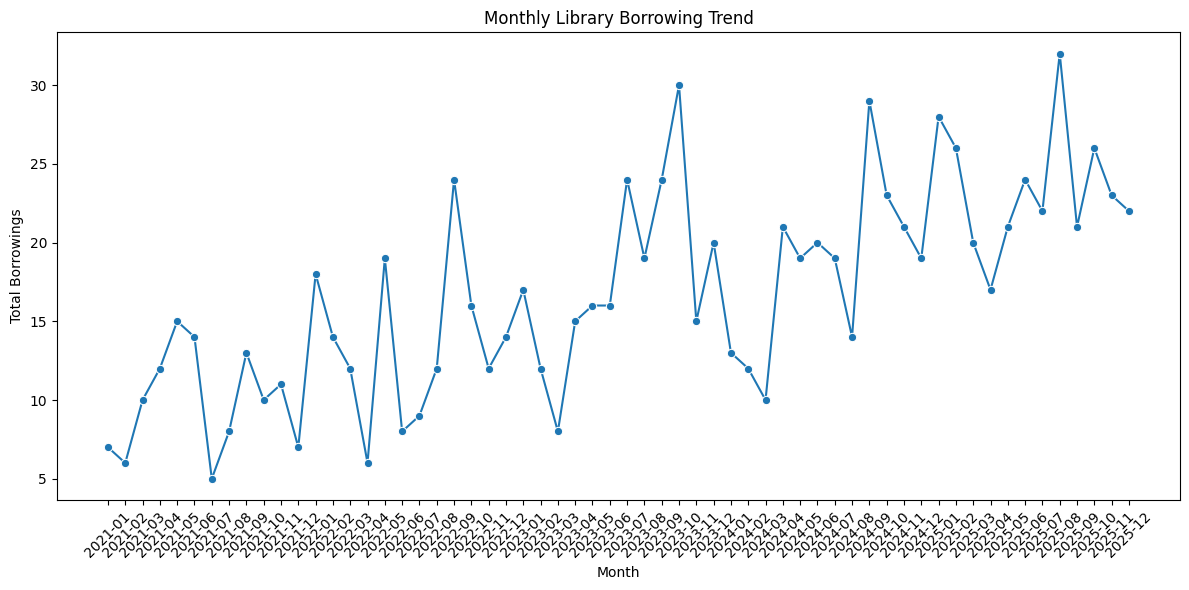

In [18]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_data,
    x='month',
    y='total_borrowings',
    marker='o'
)

plt.title('Monthly Library Borrowing Trend')
plt.xlabel('Month')
plt.ylabel('Total Borrowings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

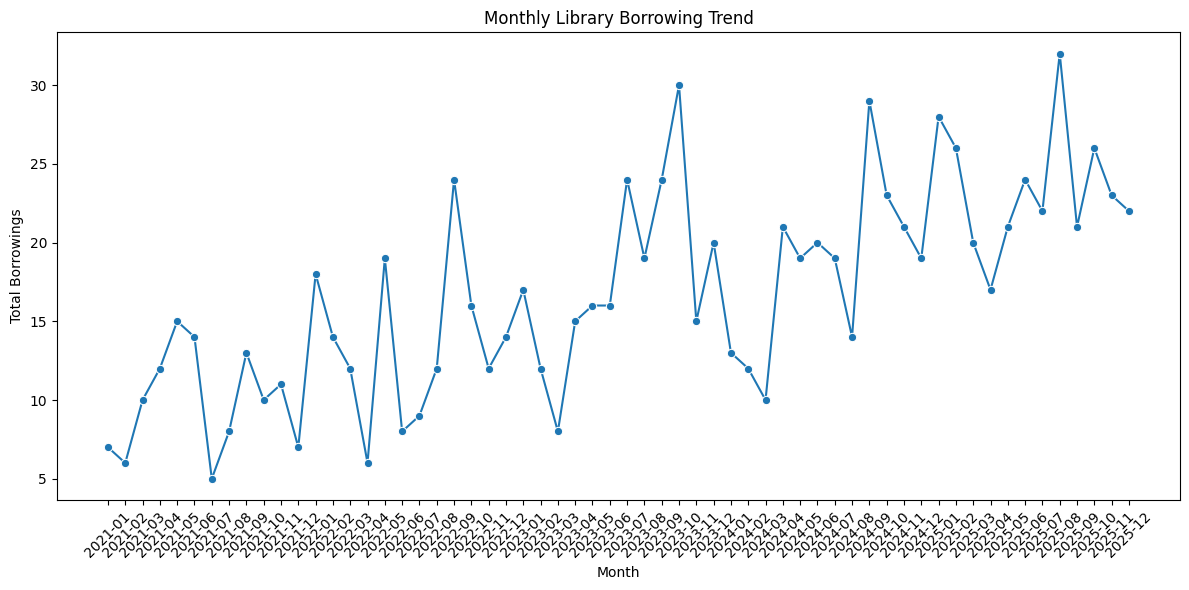

In [19]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_data,
    x='month',
    y='total_borrowings',
    marker='o'
)

plt.title('Monthly Library Borrowing Trend')
plt.xlabel('Month')
plt.ylabel('Total Borrowings')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('monthly_borrowing_trend.png', dpi=300, bbox_inches='tight')
plt.show()

In [20]:
query = """
SELECT status, COUNT(*) AS total_copies
FROM copies
GROUP BY status
ORDER BY total_copies DESC;
"""

copy_status = pd.read_sql(query, conn)
copy_status

C:\Users\me\AppData\Local\Temp\ipykernel_7156\259891773.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  copy_status = pd.read_sql(query, conn)


,status,total_copies
0,available,24
1,on_loan,14
2,lost,1
3,in_repair,1


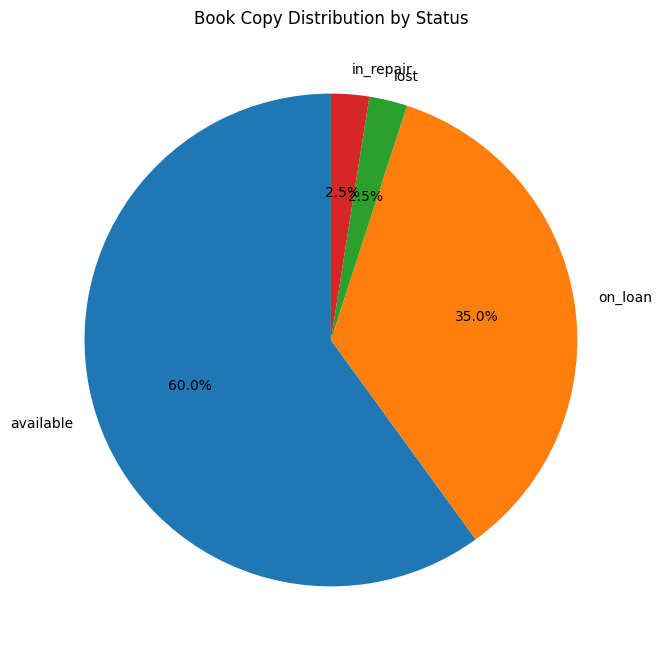

In [21]:
plt.figure(figsize=(8, 8))

plt.pie(
    copy_status['total_copies'],
    labels=copy_status['status'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Book Copy Distribution by Status')
plt.show()

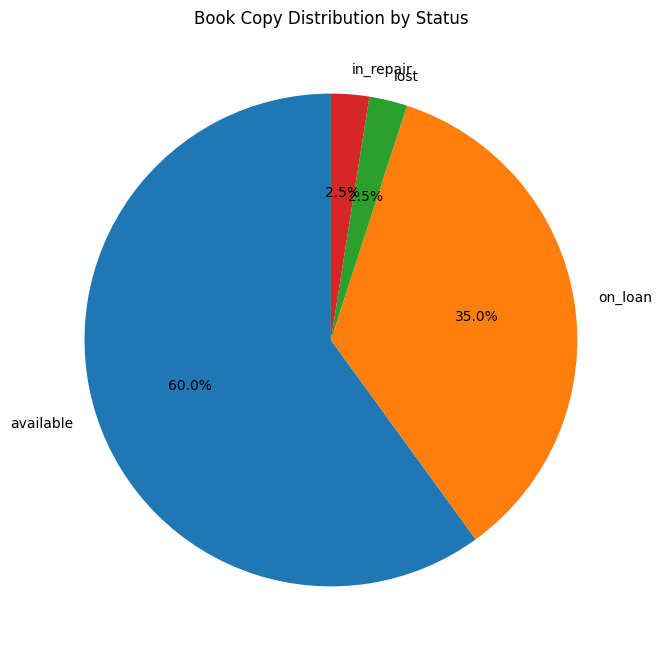

In [22]:
plt.figure(figsize=(8, 8))

plt.pie(
    copy_status['total_copies'],
    labels=copy_status['status'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Book Copy Distribution by Status')
plt.savefig('book_availability_status.png', dpi=300, bbox_inches='tight')
plt.show()

In [23]:
query = """
SELECT
    u.first_name,
    u.last_name,
    COUNT(l.id) AS total_borrowings
FROM users u
JOIN memberships m ON u.id = m.user_id
JOIN loans l ON m.id = l.membership_id
GROUP BY u.id, u.first_name, u.last_name
ORDER BY total_borrowings DESC
LIMIT 10;
"""

active_members = pd.read_sql(query, conn)
active_members

C:\Users\me\AppData\Local\Temp\ipykernel_7156\594000637.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  active_members = pd.read_sql(query, conn)


,first_name,last_name,total_borrowings
0,Alexandro,Miller,208
1,Ayden,Davis,195
2,Elaine,Mills,90
3,Eleanora,Johnson,84
4,Octavia,Stiedemann,71
5,Ernest,Waters,62
6,Angelina,Kertzmann,40
7,Maryann,Lebsack,38
8,Rigoberto,Mertz,32
9,Adrain,Feeney,25


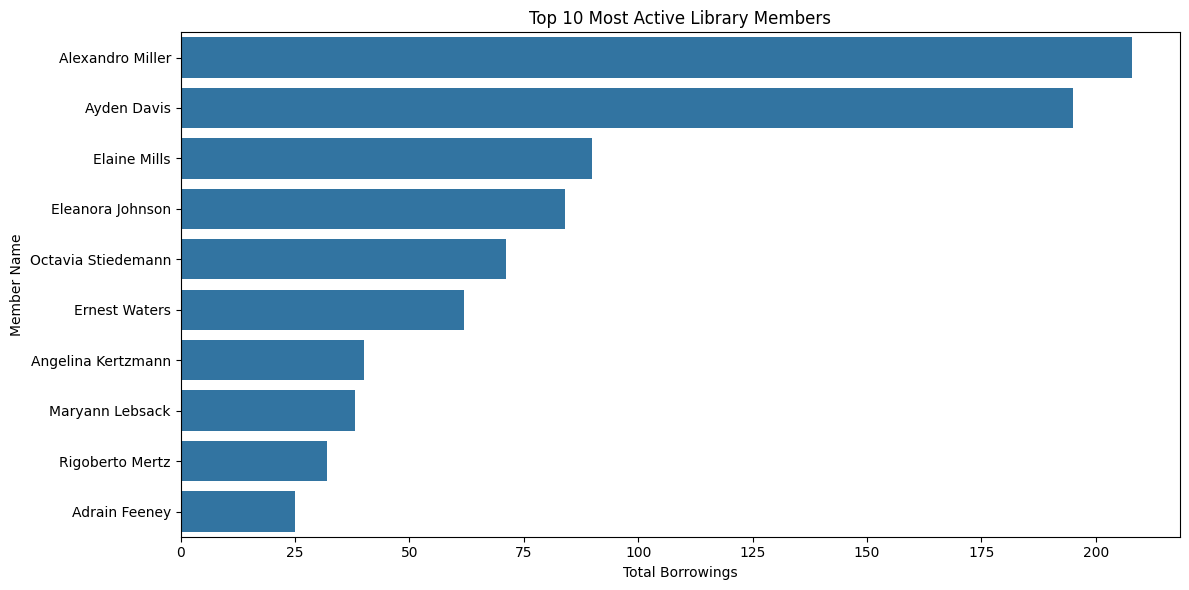

In [24]:
plt.figure(figsize=(12, 6))

active_members['member_name'] = (
    active_members['first_name'] + ' ' +
    active_members['last_name']
)

sns.barplot(
    data=active_members,
    x='total_borrowings',
    y='member_name'
)

plt.title('Top 10 Most Active Library Members')
plt.xlabel('Total Borrowings')
plt.ylabel('Member Name')
plt.tight_layout()
plt.show()

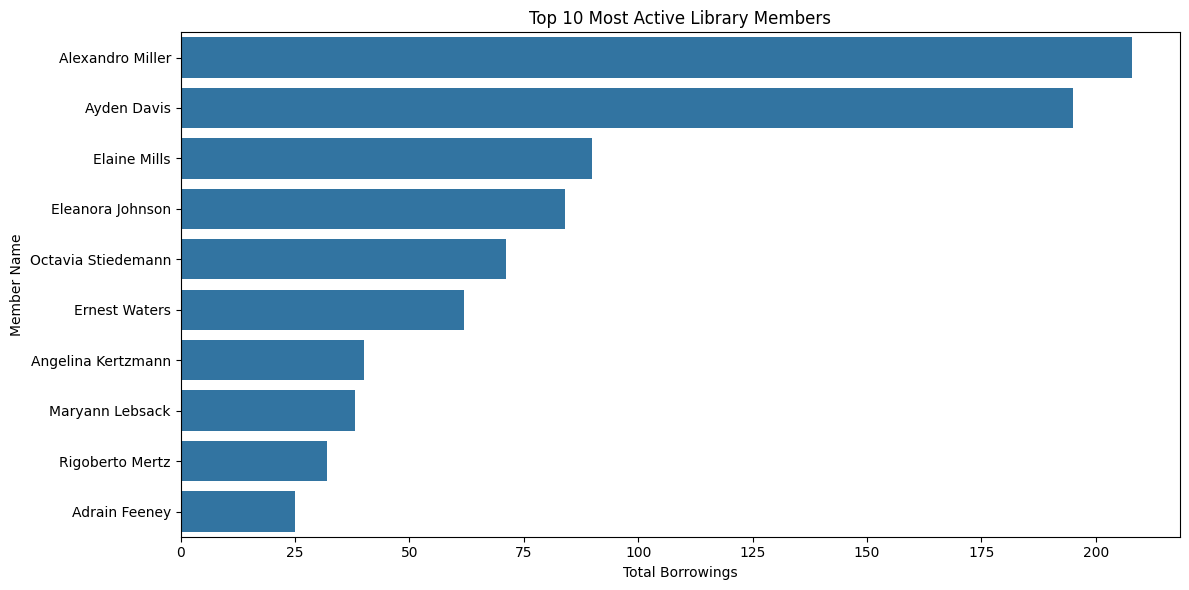

In [25]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=active_members,
    x='total_borrowings',
    y='member_name'
)

plt.title('Top 10 Most Active Library Members')
plt.xlabel('Total Borrowings')
plt.ylabel('Member Name')
plt.tight_layout()

plt.savefig('most_active_members.png', dpi=300, bbox_inches='tight')
plt.show()

In [26]:
query = """
SELECT
    SUM(amount) AS total_fines,
    SUM(paid_amount) AS total_collected,
    SUM(amount - paid_amount) AS outstanding_amount
FROM fines;
"""

fine_data = pd.read_sql(query, conn)
fine_data

C:\Users\me\AppData\Local\Temp\ipykernel_7156\1042984414.py:9: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  fine_data = pd.read_sql(query, conn)


,total_fines,total_collected,outstanding_amount
0,505.96,419.92,86.04


In [27]:
fine_summary = pd.DataFrame({
    'Fine Category': ['Total Fines', 'Collected', 'Outstanding'],
    'Amount': [
        fine_data['total_fines'][0],
        fine_data['total_collected'][0],
        fine_data['outstanding_amount'][0]
    ]
})

fine_summary

,Fine Category,Amount
0,Total Fines,505.96
1,Collected,419.92
2,Outstanding,86.04


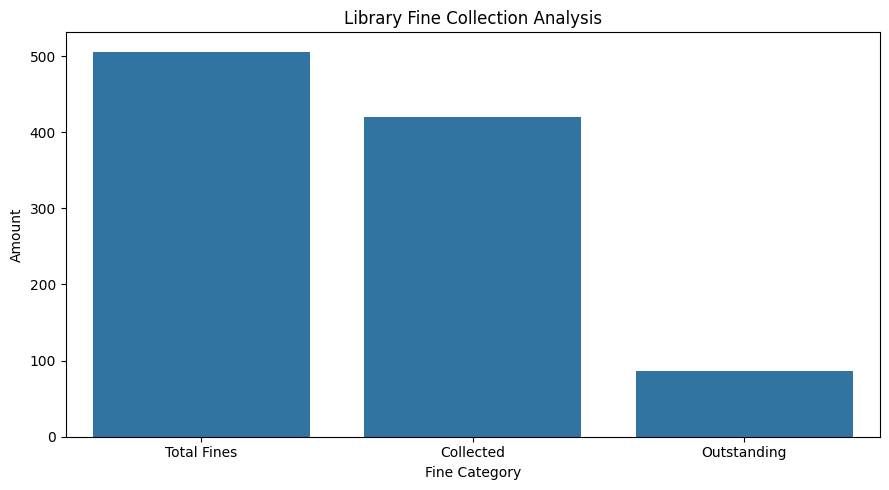

In [28]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=fine_summary,
    x='Fine Category',
    y='Amount'
)

plt.title('Library Fine Collection Analysis')
plt.xlabel('Fine Category')
plt.ylabel('Amount')
plt.tight_layout()
plt.show()

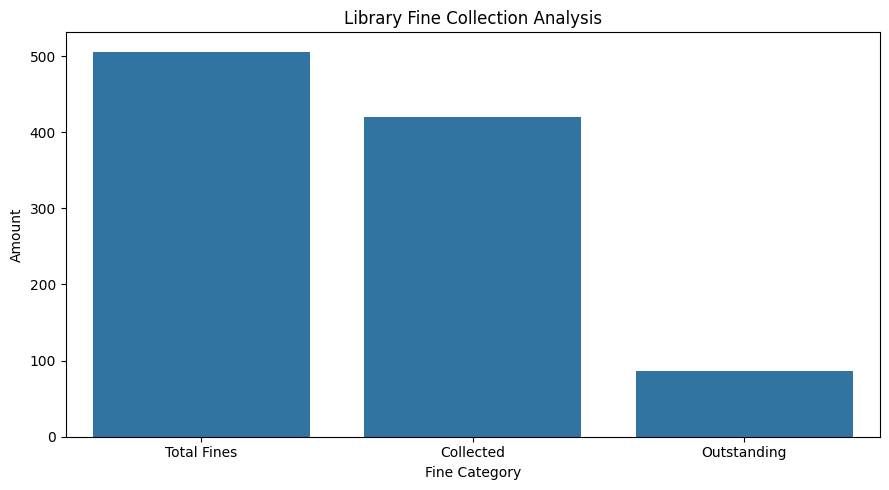

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=fine_summary,
    x='Fine Category',
    y='Amount'
)

plt.title('Library Fine Collection Analysis')
plt.xlabel('Fine Category')
plt.ylabel('Amount')
plt.tight_layout()

plt.savefig('fine_collection_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

In [30]:
query = """
SELECT
    AVG(DATEDIFF(return_date, loan_date)) AS average_days,
    MIN(DATEDIFF(return_date, loan_date)) AS minimum_days,
    MAX(DATEDIFF(return_date, loan_date)) AS maximum_days
FROM loans
WHERE return_date IS NOT NULL;
"""

duration_data = pd.read_sql(query, conn)
duration_data

C:\Users\me\AppData\Local\Temp\ipykernel_7156\3586059624.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  duration_data = pd.read_sql(query, conn)


,average_days,minimum_days,maximum_days
0,13.5701,1,26


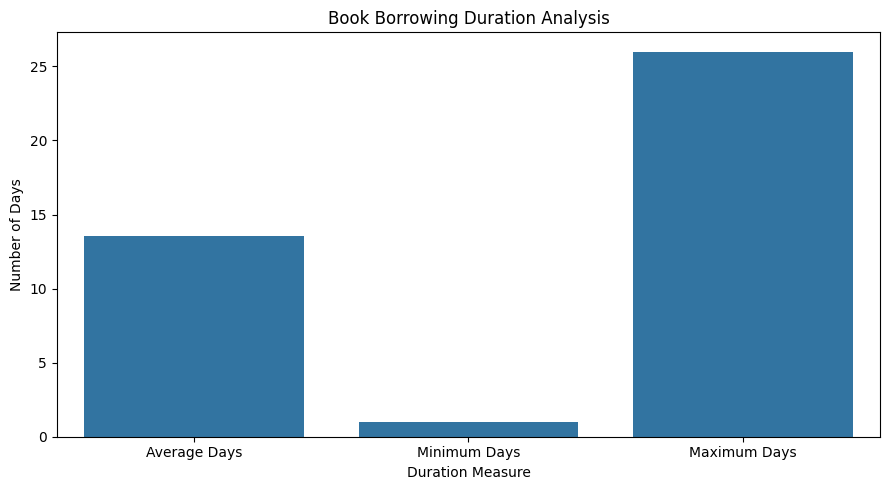

In [31]:
duration_summary = pd.DataFrame({
    'Measure': ['Average Days', 'Minimum Days', 'Maximum Days'],
    'Days': [
        duration_data['average_days'][0],
        duration_data['minimum_days'][0],
        duration_data['maximum_days'][0]
    ]
})

plt.figure(figsize=(9, 5))

sns.barplot(
    data=duration_summary,
    x='Measure',
    y='Days'
)

plt.title('Book Borrowing Duration Analysis')
plt.xlabel('Duration Measure')
plt.ylabel('Number of Days')
plt.tight_layout()
plt.show()

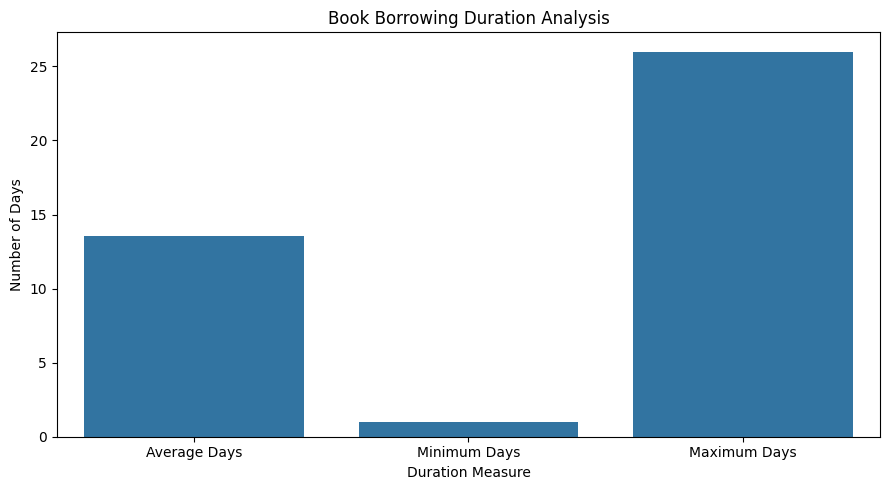

In [32]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=duration_summary,
    x='Measure',
    y='Days'
)

plt.title('Book Borrowing Duration Analysis')
plt.xlabel('Duration Measure')
plt.ylabel('Number of Days')
plt.tight_layout()

plt.savefig('borrowing_duration.png', dpi=300, bbox_inches='tight')
plt.show()

In [33]:
conn.close()
print("Database connection closed successfully!")

Database connection closed successfully!
